In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

In [14]:
df = pd.read_csv("malware_features_dataset.csv")

In [15]:
df.head

<bound method NDFrame.head of     sample_id  true_family       sub_variant  file_size_kb  pe_header_entropy  \
0     MAL_001   Ransomware  WannaCry_variant           389           7.525434   
1     MAL_002   Ransomware   LockBit_variant           372           7.892629   
2     MAL_003   Ransomware  WannaCry_variant           304           7.328979   
3     MAL_004   Ransomware   LockBit_variant           329           7.599033   
4     MAL_005   Ransomware  WannaCry_variant           301           7.487077   
..        ...          ...               ...           ...                ...   
105   MAL_106  InfoStealer        RedLine_v1           317           5.724339   
106   MAL_107  InfoStealer        RedLine_v2           328           6.108041   
107   MAL_108  InfoStealer        RedLine_v1           286           6.301441   
108   MAL_109  InfoStealer        RedLine_v2           270           6.202264   
109   MAL_110  InfoStealer        RedLine_v1           265           5.941158  

In [16]:
df.tail

<bound method NDFrame.tail of     sample_id  true_family       sub_variant  file_size_kb  pe_header_entropy  \
0     MAL_001   Ransomware  WannaCry_variant           389           7.525434   
1     MAL_002   Ransomware   LockBit_variant           372           7.892629   
2     MAL_003   Ransomware  WannaCry_variant           304           7.328979   
3     MAL_004   Ransomware   LockBit_variant           329           7.599033   
4     MAL_005   Ransomware  WannaCry_variant           301           7.487077   
..        ...          ...               ...           ...                ...   
105   MAL_106  InfoStealer        RedLine_v1           317           5.724339   
106   MAL_107  InfoStealer        RedLine_v2           328           6.108041   
107   MAL_108  InfoStealer        RedLine_v1           286           6.301441   
108   MAL_109  InfoStealer        RedLine_v2           270           6.202264   
109   MAL_110  InfoStealer        RedLine_v1           265           5.941158  

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110 entries, 0 to 109
Data columns (total 12 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   sample_id                        110 non-null    object 
 1   true_family                      110 non-null    object 
 2   sub_variant                      110 non-null    object 
 3   file_size_kb                     110 non-null    int64  
 4   pe_header_entropy                110 non-null    float64
 5   num_sections                     110 non-null    int64  
 6   imported_crypto_apis             110 non-null    int64  
 7   imported_file_io_apis            110 non-null    int64  
 8   imported_process_injection_apis  110 non-null    int64  
 9   imported_network_apis            110 non-null    int64  
 10  imported_hooking_apis            110 non-null    int64  
 11  num_packed_sections              110 non-null    int64  
dtypes: float64(1), int64(8

In [19]:
df.isnull().sum()

sample_id                          0
true_family                        0
sub_variant                        0
file_size_kb                       0
pe_header_entropy                  0
num_sections                       0
imported_crypto_apis               0
imported_file_io_apis              0
imported_process_injection_apis    0
imported_network_apis              0
imported_hooking_apis              0
num_packed_sections                0
dtype: int64

In [20]:
features = ['pe_header_entropy', 'imported_crypto_apis', 'imported_file_io_apis', 'imported_network_apis', 'imported_hooking_apis']
data = df[features].values

In [21]:
Z = linkage(data, method='ward')

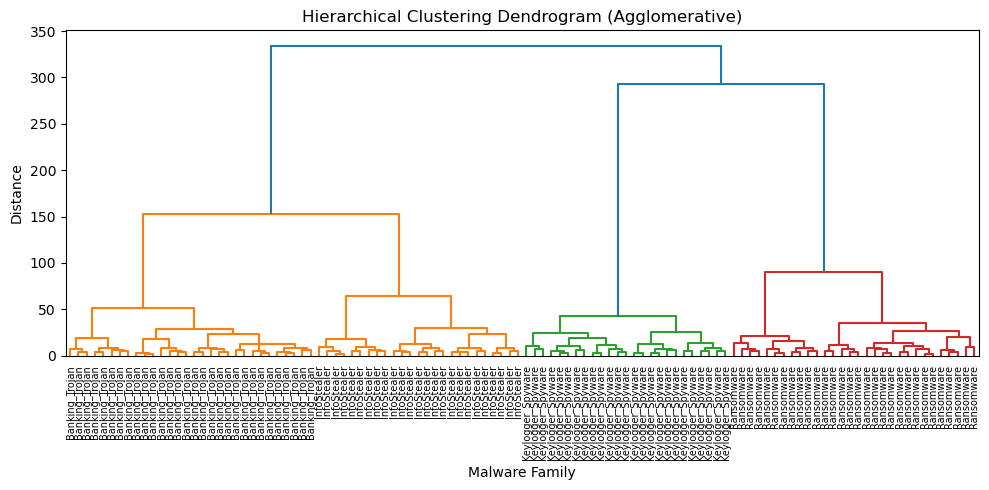

In [22]:
plt.figure(figsize=(10, 5))
dendrogram(Z, labels=df['true_family'].values, leaf_rotation=90, leaf_font_size=7)
plt.title("Hierarchical Clustering Dendrogram (Agglomerative)")
plt.xlabel("Malware Family")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

In [27]:
Z = linkage(data, method='complete')

In [28]:
print("Linkage Matrix:")
print(Z)

Linkage Matrix:
[[ 89.         101.           1.41719074   2.        ]
 [  8.          11.           1.73916564   2.        ]
 [ 34.          52.           1.92824045   2.        ]
 [  5.          27.           2.46457973   2.        ]
 [ 86.          87.           2.47726974   2.        ]
 [ 64.          72.           2.67868591   2.        ]
 [ 62.          80.           2.69349613   2.        ]
 [ 69.          82.           3.00000174   2.        ]
 [ 54.         112.           3.00010598   3.        ]
 [ 61.          66.           3.00089803   2.        ]
 [ 14.          29.           3.00788086   2.        ]
 [ 36.          53.           3.16250637   2.        ]
 [ 40.          57.           3.32293025   2.        ]
 [ 32.          46.           3.37176876   2.        ]
 [ 39.          50.           3.50786089   2.        ]
 [ 92.         106.           3.52771122   2.        ]
 [100.         104.           3.61204535   2.        ]
 [ 35.          55.           3.64222771   2.    

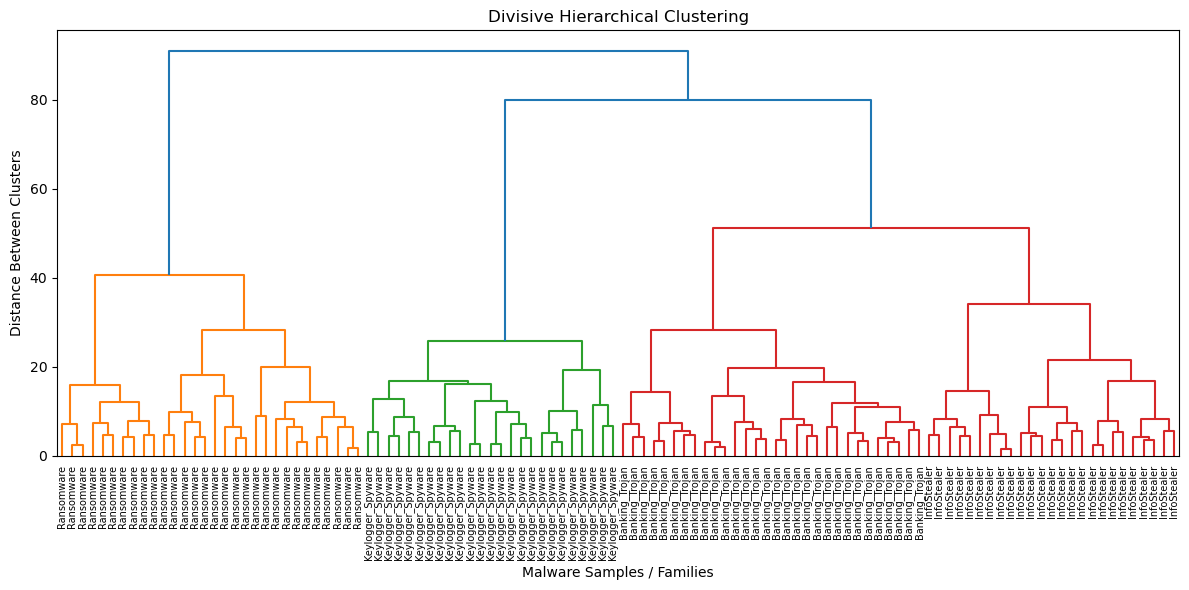

In [29]:
plt.figure(figsize=(12, 6))
dendrogram(Z, labels=df['true_family'].values, leaf_rotation=90, leaf_font_size=7)
plt.title("Divisive Hierarchical Clustering")
plt.xlabel("Malware Samples / Families")
plt.ylabel("Distance Between Clusters")
plt.tight_layout()
plt.show()